# Predicting Power Plant Energy Output
**Combined Cycle Power Plant (CCPP) dataset** — Linear Regression vs Random Forest with 5-fold cross-validation.

- **Target:** `PE` – net hourly electrical energy output (MW)
- **Features:** `AT` ambient temperature (°C), `V` exhaust vacuum (cm Hg), `AP` ambient pressure (mbar), `RH` relative humidity (%)

> Put `CCPP_data.csv` in the same folder as this notebook (or change `DATA_PATH` below).

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

%matplotlib inline
RANDOM_STATE = 42

## 2. Load the data

In [2]:
DATA_PATH = 'CCPP_data.csv'
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')   # utf-8-sig strips the hidden BOM before 'AT'
print('Shape:', df.shape)
df.head()

Shape: (9568, 5)


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [3]:
df.info()
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nDuplicate rows:', df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB

Missing values per column:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Duplicate rows: 41


In [4]:
df.describe().round(2)

,AT,V,AP,RH,PE
count,9568.00,9568.00,9568.00,9568.00,9568.00
mean,19.65,54.31,1013.26,73.31,454.37
std,7.45,12.71,5.94,14.60,17.07
min,1.81,25.36,992.89,25.56,420.26
25%,13.51,41.74,1009.10,63.33,439.75
50%,20.34,52.08,1012.94,74.97,451.55
75%,25.72,66.54,1017.26,84.83,468.43
max,37.11,81.56,1033.30,100.16,495.76


## 3. Feature correlation analysis

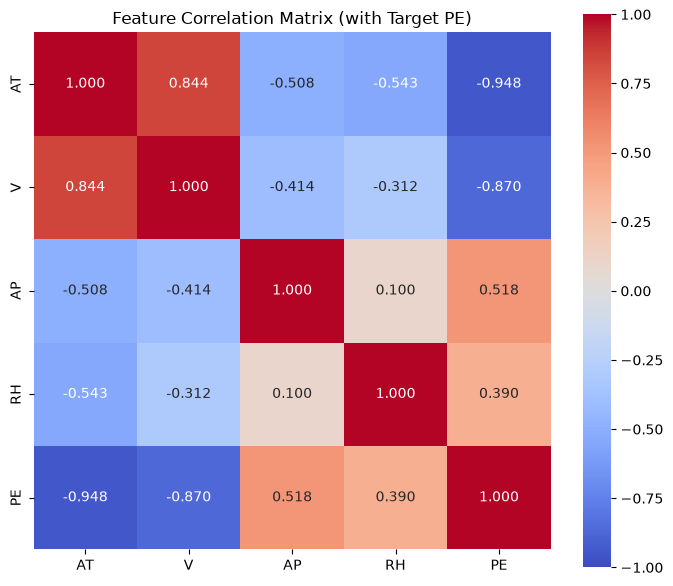

Correlation with PE (strongest first):
AT   -0.948
V    -0.870
AP    0.518
RH    0.390
Name: PE, dtype: float64


In [5]:
corr = df.corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Feature Correlation Matrix (with Target PE)')
plt.tight_layout()
plt.show()

print('Correlation with PE (strongest first):')
print(corr['PE'].drop('PE').sort_values(key=abs, ascending=False).round(3))

## 4. Train / test split (80 / 20)

In [6]:
features = ['AT', 'V', 'AP', 'RH']
X = df[features]
y = df['PE']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f'Training samples: {len(X_train)}')
print(f'Test samples:     {len(X_test)}')

Training samples: 7654
Test samples:     1914


## 5. Define the models

In [7]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
}

## 6. 5-fold cross-validation on the training set

In [8]:
cv_rmse = {}
for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5,
                             scoring='neg_root_mean_squared_error')
    cv_rmse[name] = -scores.mean()
    print(f'{name:<18} CV RMSE: {-scores.mean():.4f} MW  (± {scores.std():.4f})')

Linear Regression  CV RMSE: 4.5724 MW  (± 0.1114)
Random Forest      CV RMSE: 3.4624 MW  (± 0.1544)


## 7. Train on the full training set and evaluate on the held-out test set

In [9]:
results, predictions = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results[name] = {
        'CV_RMSE':   cv_rmse[name],
        'Test_RMSE': np.sqrt(mean_squared_error(y_test, y_pred)),
        'Test_R2':   r2_score(y_test, y_pred),
    }
    print(f"{name:<18} Test RMSE: {results[name]['Test_RMSE']:.4f} MW | R²: {results[name]['Test_R2']:.4f}")

Linear Regression  Test RMSE: 4.5026 MW | R²: 0.9301
Random Forest      Test RMSE: 3.2446 MW | R²: 0.9637


## 8. Actual vs predicted

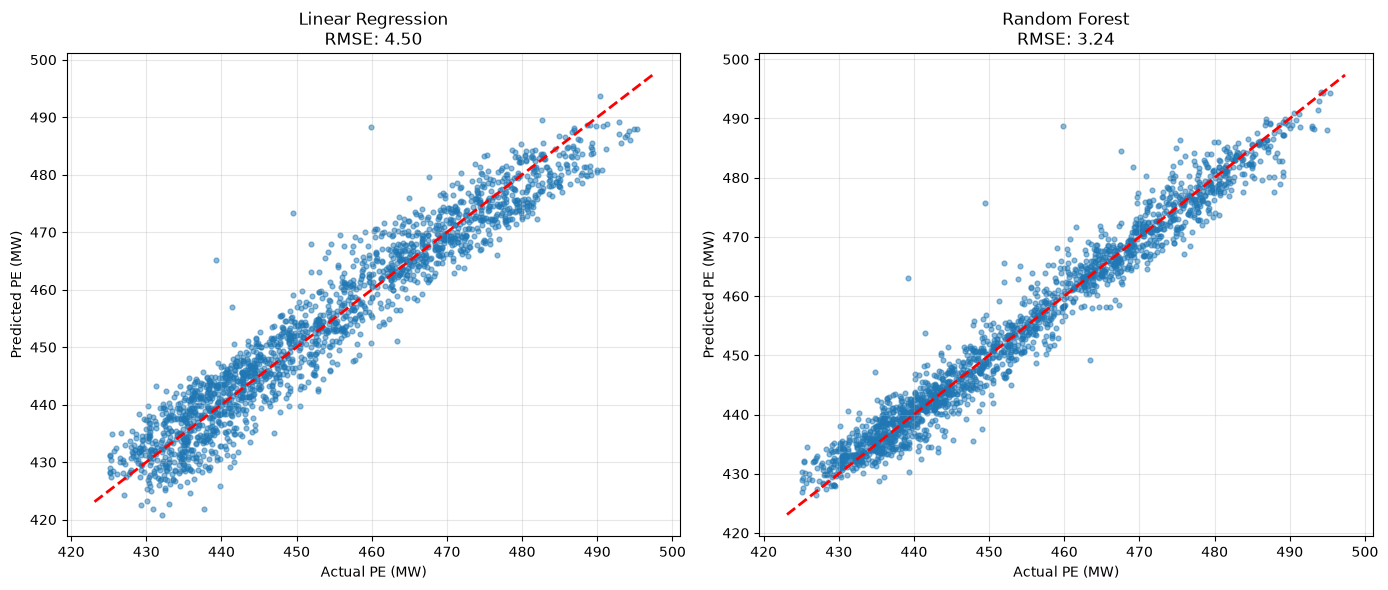

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lims = [y_test.min() - 2, y_test.max() + 2]
for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.5, s=12)
    ax.plot(lims, lims, 'r--', lw=2)
    ax.set_title(f"{name}\nRMSE: {results[name]['Test_RMSE']:.2f}")
    ax.set_xlabel('Actual PE (MW)')
    ax.set_ylabel('Predicted PE (MW)')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Linear Regression coefficients vs Random Forest feature importance

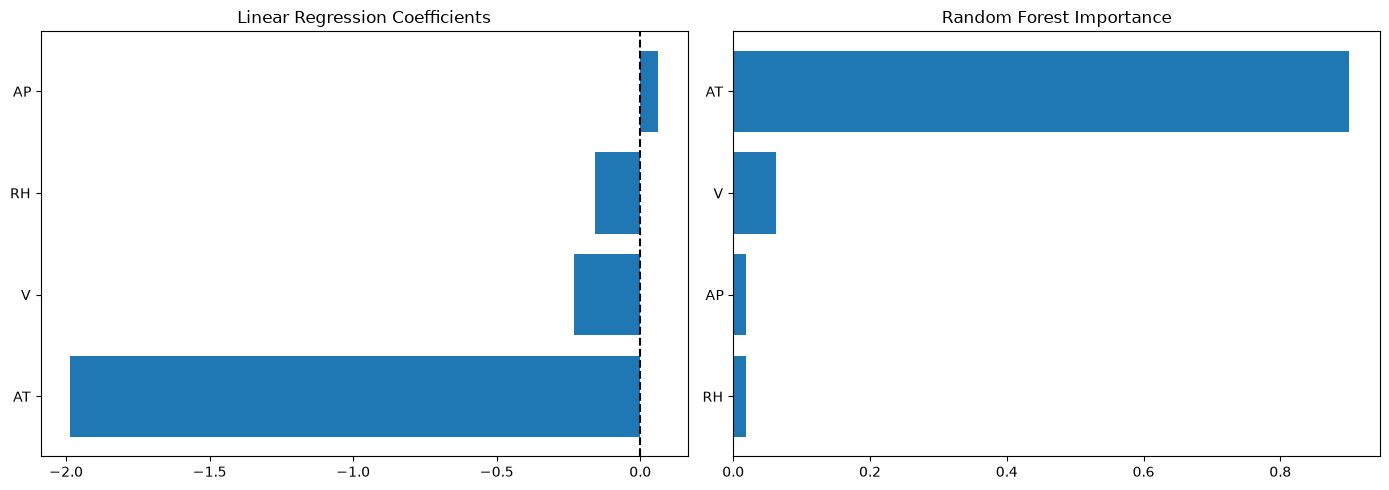

Linear Regression intercept: 454.5691
    LR_coefficient  RF_importance
AP          0.0622         0.0184
AT         -1.9859         0.9008
RH         -0.1581         0.0181
V          -0.2321         0.0628


In [11]:
lr = models['Linear Regression']
rf = models['Random Forest']

coefs = pd.Series(lr.coef_, index=features).sort_values()
importances = pd.Series(rf.feature_importances_, index=features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(coefs.index, coefs.values)
axes[0].axvline(0, color='black', linestyle='--')
axes[0].set_title('Linear Regression Coefficients')
axes[1].barh(importances.index, importances.values)
axes[1].set_title('Random Forest Importance')
plt.tight_layout()
plt.show()

print('Linear Regression intercept:', round(lr.intercept_, 4))
print(pd.DataFrame({'LR_coefficient': coefs.round(4), 'RF_importance': importances.round(4)}))

## 10. Summary and final model

In [14]:
summary = pd.DataFrame(results).T.round(4)
print('SUMMARY:')
print(summary)

best = summary['Test_RMSE'].idxmin()
lr_rmse, rf_rmse = summary.loc['Linear Regression', 'Test_RMSE'], summary.loc['Random Forest', 'Test_RMSE']
print(f'\n FINAL MODEL: {best}')
print(f'Random Forest test RMSE is {(lr_rmse - rf_rmse) / lr_rmse * 100:.1f}% lower than Linear Regression')

SUMMARY:
                   CV_RMSE  Test_RMSE  Test_R2
Linear Regression   4.5724     4.5026   0.9301
Random Forest       3.4624     3.2446   0.9637

 FINAL MODEL: Random Forest
Random Forest test RMSE is 27.9% lower than Linear Regression


## 11. Predict on new conditions (example)

In [15]:
new_data = pd.DataFrame({'AT': [15.0, 30.0], 'V': [40.0, 70.0],
                         'AP': [1015.0, 1010.0], 'RH': [75.0, 50.0]})
new_data['Predicted_PE (MW)'] = models[best].predict(new_data[features]).round(2)
new_data

,AT,V,AP,RH,Predicted_PE (MW)
0,15.0,40.0,1015.0,75.0,466.07
1,30.0,70.0,1010.0,50.0,433.77
